In [ ]:
Red Wine Quality: Classification Analysis

**Goal:** predict whether a red Vinho Verde wine is **"good" (quality ≥ 7)** from its 11 laboratory measurements.
    
**Dataset:** UCI Wine Quality (red), the same data as Kaggle's *Red Wine Quality* — 1,599 wines, 11 physicochemical features, and a sensory score
(median of ≥3 expert tasters).

**Structure:** every step prints its own result and is followed by a short *check* so each step is verified before moving on.
    
| Step | Topic |
|---|---|
| 1 | Problem statement and target analysis |
| 2 | Cleaning: missing values, duplicates, categorical check |
| 3 | Outliers (histograms, boxplots, IQR) |
| 4 | Feature engineering |
| 5 | Feature selection: variance, ANOVA, chi-squared, correlation, VIF |
| 6 | Split, scaling, dummy variables |
| 7 | Balancing and model comparison |
| 8 | Final test-set evaluation |
| 9 | Why the model is only mediocre |
| 10 | Summary |

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import f_classif, chi2
from sklearn.model_selection import train_test_split, cross_validate, cross_val_predict, StratifiedKFold
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import make_pipeline as sk_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, 
                             average_precision_score, confusion_matrix)
try: 
    from imblearn.pipeline import make_pipeline 
    from imblearn.over_sampling import SMOTE
except ImportError:                       # pip install imbalanced-learn 
    import subprocess, sys 
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"]) 
    from imblearn.pipeline import make_pipeline 
    from imblearn.over_sampling import SMOTE
pd.set_option("display.width", 140)
SEED = 42

In [ ]:
Step 1 — Problem statement and target analysis

In [2]:
URL = "https://www.kaggle.com/datasets/yasserh/wine-quality-dataset/data"
try: 
    df = pd.read_csv(URL)
except Exception: 
    df = pd.read_csv("winequality-red.csv")          # fallback if offline
    
print("Shape:", df.shape)
print("Dtypes:", df.dtypes.value_counts().to_dict())
print()
print(df.drop(columns="quality").describe().T[["mean","std","min","max"]].round(3).to_string())

Shape: (1599, 12)
Dtypes: {dtype('float64'): 11, dtype('int64'): 1}

                        mean     std    min      max
fixed acidity          8.320   1.741  4.600   15.900
volatile acidity       0.528   0.179  0.120    1.580
citric acid            0.271   0.195  0.000    1.000
residual sugar         2.539   1.410  0.900   15.500
chlorides              0.087   0.047  0.012    0.611
free sulfur dioxide   15.875  10.460  1.000   72.000
total sulfur dioxide  46.468  32.895  6.000  289.000
density                0.997   0.002  0.990    1.004
pH                     3.311   0.154  2.740    4.010
sulphates              0.658   0.170  0.330    2.000
alcohol               10.423   1.066  8.400   14.900


Target 'quality' counts:
 quality
3     10
4     53
5    681
6    638
7    199
8     18

Share (%):
 quality
3     0.6
4     3.3
5    42.6
6    39.9
7    12.4
8     1.1

Binary target good = (quality >= 7): 217 good vs 1382 not good -> 13.6% positive


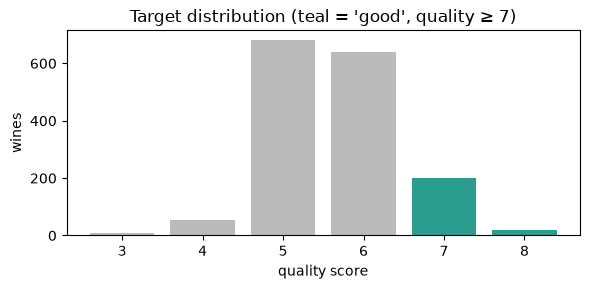

In [3]:
vc = df.quality.value_counts().sort_index()
print("Target 'quality' counts:\n", vc.to_string())
print("\nShare (%):\n", (vc / len(df) * 100).round(1).to_string())
good = df.quality >= 7
print(f"\nBinary target good = (quality >= 7): {good.sum()} good vs {(~good).sum()} not good -> {good.mean():.1%} positive")
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(vc.index.astype(str), vc.values, color=["#bbb"]*4 + ["#2a9d8f"]*2)
ax.set_xlabel("quality score"); ax.set_ylabel("wines"); ax.set_title("Target distribution (teal = 'good', quality ≥ 7)")
plt.tight_layout(); plt.show()

In [ ]:
**Check.** 1,599 wines, all-numeric features, no categorical columns. 82% of wines score 5 or 6; scores 3, 4 and 8 have only 10, 53 and 18 samples —
too few for a reliable 6-class model. I therefore frame this as **binary classification** (good = quality ≥ 7). Only **13.6%** are good, so the
classes are imbalanced and a model that always answers "not good" would score 86.4% accuracy. Accuracy will not be the main metric.

In [ ]:
Step 2 — Basic cleaning

In [4]:
print("Missing values:", int(df.isna().sum().sum()))
print("Column names with stray whitespace:", [c for c in df.columns if c != c.strip()] or "none")
print("Duplicate rows:", df.duplicated().sum(), f"({df.duplicated().mean():.1%})")
d = df[df.duplicated(keep=False)]
print("Quality distribution of duplicated rows:", d.quality.value_counts().sort_index().to_dict())
print("Impossible values (negatives / density<=0 / pH outside 0-14):",
      int((df.drop(columns='quality') < 0).sum().sum()), int((df.density <= 0).sum()), int(((df.pH < 0) | (df.pH > 14)).sum()))
print("Zeros in citric acid:", (df['citric acid'] == 0).sum(), "(plausible: none added)")
print("Categorical columns to check for inconsistent labels:", list(df.select_dtypes(exclude='number').columns) or "none")

Missing values: 0
Column names with stray whitespace: none
Duplicate rows: 240 (15.0%)
Quality distribution of duplicated rows: {5: 201, 6: 196, 7: 61, 8: 2}
Impossible values (negatives / density<=0 / pH outside 0-14): 0 0 0
Zeros in citric acid: 132 (plausible: none added)
Categorical columns to check for inconsistent labels: none


In [ ]:
**Check.** No missing values, no impossible values, no categorical columns (so no inconsistent labels to fix). But **240 rows (15%) are exact
duplicates** — with 11 measurements at this precision, two different wines matching exactly is implausible. Left in, they could land in both train and
test and inflate scores, so they are removed.

In [5]:
n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows: {n0} -> {len(df)} (removed {n0 - len(df)})")
print("Duplicates remaining:", df.duplicated().sum())
print(f"Good wines now: {(df.quality>=7).sum()} / {len(df)} = {(df.quality>=7).mean():.1%} (was 13.6%)")

Rows: 1599 -> 1359 (removed 240)
Duplicates remaining: 0
Good wines now: 184 / 1359 = 13.5% (was 13.6%)


In [ ]:
Step 3 — Outliers (histograms, boxplots, IQR)

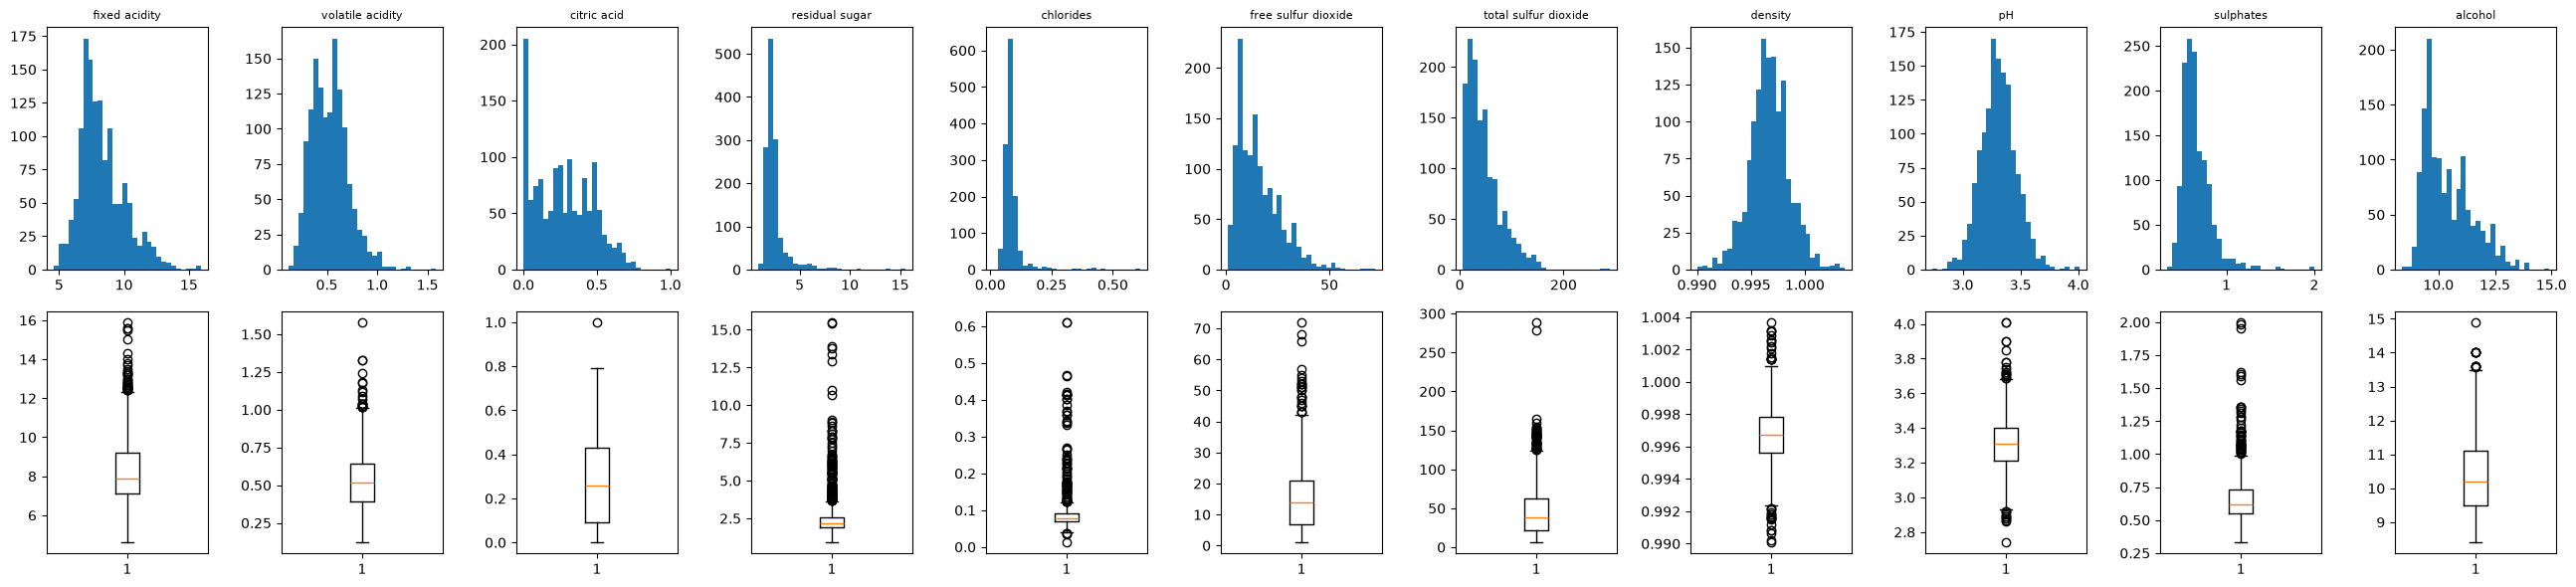

feature                  skew IQR outliers      %
fixed acidity            0.94           41   3.0%
volatile acidity         0.73           19   1.4%
citric acid              0.31            1   0.1%
residual sugar           4.55          126   9.3%
chlorides                5.50           87   6.4%
free sulfur dioxide      1.23           26   1.9%
total sulfur dioxide     1.54           45   3.3%
density                  0.04           35   2.6%
pH                       0.23           28   2.1%
sulphates                2.41           55   4.0%
alcohol                  0.86           12   0.9%


In [6]:
X = df.drop(columns="quality")
fig, ax = plt.subplots(2, 11, figsize=(26, 6))
for i, c in enumerate(X.columns): 
    ax[0, i].hist(X[c], bins=30); ax[0, i].set_title(c, fontsize=8) 
    ax[1, i].boxplot(X[c])
plt.tight_layout(); plt.show()

print(f"{'feature':22s} {'skew':>6s} {'IQR outliers':>12s} {'%':>6s}")
for c in X.columns: 
    q1, q3 = X[c].quantile([.25, .75]); i = q3 - q1 
    n = ((X[c] < q1 - 1.5*i) | (X[c] > q3 + 1.5*i)).sum() 
    print(f"{c:22s} {X[c].skew():6.2f} {n:12d} {n/len(X):6.1%}")

In [ ]:
**Check.** `residual sugar` (skew 4.6) and `chlorides` (skew 5.5) have long right tails — genuinely sweeter or saltier wines, not errors. Before
deleting anything, measure what the usual 1.5×IQR rule would cost.

In [7]:
good = df.quality >= 7
def flag(k): 
    q1, q3 = X.quantile(.25), X.quantile(.75); i = q3 - q1 
    return ((X < q1 - k*i) | (X > q3 + k*i)).any(axis=1)
for k in (1.5, 2.5, 3.0): 
    m = flag(k) 
    print(f"{k}xIQR any-feature: removes {m.sum():4d} rows ({m.mean():.1%}) | good wines lost: " 
          f"{(m & good).sum():3d}/{good.sum()} ({(m & good).sum()/good.sum():.1%}) | positive rate after: {good[~m].mean():.1%}")

1.5xIQR any-feature: removes  340 rows (25.0%) | good wines lost:  58/184 (31.5%) | positive rate after: 12.4%
2.5xIQR any-feature: removes  171 rows (12.6%) | good wines lost:  27/184 (14.7%) | positive rate after: 13.2%
3.0xIQR any-feature: removes  139 rows (10.2%) | good wines lost:  21/184 (11.4%) | positive rate after: 13.4%


In [ ]:
**Check.** The standard 1.5×IQR rule would delete **25% of the data and 31.5% of the good wines** — too costly for the minority class we are trying to
predict. I use the stricter **3×IQR rule for extreme outliers** instead.

In [8]:
m = flag(3.0)
df_clean = df[~m].reset_index(drop=True)
print(f"Rows: {len(df)} -> {len(df_clean)}")
print("Good wines:", (df_clean.quality >= 7).sum(), f"({(df_clean.quality >= 7).mean():.1%})")
print("\nSkew before -> after:")
for c in ["residual sugar", "chlorides", "sulphates", "total sulfur dioxide"]: 
    print(f" {c:22s} {df[c].skew():5.2f} -> {df_clean[c].skew():5.2f}")

Rows: 1359 -> 1220
Good wines: 163 (13.4%)

Skew before -> after:
 residual sugar          4.55 ->  1.40
 chlorides               5.50 ->  0.58
 sulphates               2.41 ->  1.07
 total sulfur dioxide    1.54 ->  1.21


In [ ]:
Step 4 — Feature engineering

In [9]:
fe = df_clean.copy()
fe["good"] = (fe.quality >= 7).astype(int)
fe["free_total_ratio"] = fe["free sulfur dioxide"] / fe["total sulfur dioxide"]
fe["bound_so2"] = fe["total sulfur dioxide"] - fe["free sulfur dioxide"]
fe["total_acidity"] = fe["fixed acidity"] + fe["volatile acidity"] + fe["citric acid"]
fe["sulphates_per_chl"] = fe["sulphates"] / fe["chlorides"]
fe["alcohol_x_sulph"] = fe["alcohol"] * fe["sulphates"]
for c in ["residual sugar", "chlorides", "sulphates", "total sulfur dioxide", "free sulfur dioxide"]: 
    fe["log_" + c.replace(" ", "_")] = np.log1p(fe[c])
    
c = fe.drop(columns="quality").corr()["good"]
print("Correlation with 'good' (raw -> log version):")
for raw, new in [("sulphates","log_sulphates"), ("chlorides","log_chlorides"), ("residual sugar","log_residual_sugar"), 
                 ("total sulfur dioxide","log_total_sulfur_dioxide"), ("free sulfur dioxide","log_free_sulfur_dioxide")]: 
    print(f" {raw:22s} {c[raw]:+.3f} -> {new:26s} {c[new]:+.3f}")
print("\nNew ratio / interaction features:")
for n in ["free_total_ratio", "bound_so2", "total_acidity", "sulphates_per_chl", "alcohol_x_sulph"]: 
    print(f" {n:20s} {c[n]:+.3f}")
print("\nFor reference, alcohol alone:", f"{c['alcohol']:+.3f}")

Correlation with 'good' (raw -> log version):
 sulphates              +0.305 -> log_sulphates              +0.310
 chlorides              -0.141 -> log_chlorides              -0.143
 residual sugar         +0.025 -> log_residual_sugar         +0.020
 total sulfur dioxide   -0.154 -> log_total_sulfur_dioxide   -0.166
 free sulfur dioxide    -0.065 -> log_free_sulfur_dioxide    -0.077

New ratio / interaction features:
 free_total_ratio     +0.139
 bound_so2            -0.161
 total_acidity        +0.084
 sulphates_per_chl    +0.346
 alcohol_x_sulph      +0.435

For reference, alcohol alone: +0.408


In [ ]:
**Check.** Log transforms barely change the correlations (≤ 0.01). The interactions are the more interesting finds: `alcohol_x_sulph` (+0.435) beats 
alcohol alone (+0.408), and `sulphates_per_chl` (+0.346) beats both of its parts. Whether they survive collinearity checks is decided in Step 5.

In [ ]:
Step 5 — Feature selection

In [ ]:
5a. Variance (zero or near-zero variance?)

In [10]:
Xf = fe.drop(columns=["quality", "good"])
v = pd.Series(MinMaxScaler().fit_transform(Xf).var(axis=0), index=Xf.columns).sort_values()
print("Min-max scaled variance (lowest 8):"); print(v.head(8).round(4).to_string())
print("\nZero-variance features:", list(v[v == 0].index) or "none")
print("Highest/lowest variance ratio:", round(v.max() / v.min(), 1))

Min-max scaled variance (lowest 8):
sulphates_per_chl     0.0100
log_chlorides         0.0144
chlorides             0.0144
pH                    0.0205
volatile acidity      0.0222
density               0.0223
sulphates             0.0227
log_residual_sugar    0.0234

Zero-variance features: none
Highest/lowest variance ratio: 6.3


In [ ]:
**Check.** Raw variance depends on units (density varies by 0.002, total SO₂ by 33), so features are compared after min-max scaling. No feature has
zero or near-zero variance; variance alone removes nothing.

In [ ]:
5b. Relevance to the target: ANOVA F-test and chi-squared

In [11]:
yf = fe.good
F, p = f_classif(Xf, yf)
ch, pc = chi2(MinMaxScaler().fit_transform(Xf), yf)       # chi2 needs non-negative inputs
r = pd.DataFrame({"feature": Xf.columns, "ANOVA_F": F, "ANOVA_p": p, "chi2": ch, "chi2_p": pc}).sort_values("ANOVA_F", ascending=False)
print(r.round(4).to_string(index=False))
print("\nNot significant on ANOVA (p>=0.05):", list(r[r.ANOVA_p >= 0.05].feature))
print("Not significant on chi2 (p>=0.05):", list(r[r.chi2_p >= 0.05].feature))

                 feature  ANOVA_F  ANOVA_p    chi2  chi2_p
         alcohol_x_sulph 283.8674   0.0000 17.0630  0.0000
                 alcohol 243.7721   0.0000 20.2243  0.0000
       sulphates_per_chl 165.4864   0.0000  9.3965  0.0022
           log_sulphates 129.1296   0.0000  6.8449  0.0089
               sulphates 125.0968   0.0000  7.3506  0.0067
        volatile acidity  93.2108   0.0000  5.7233  0.0167
             citric acid  50.2194   0.0000  8.7739  0.0031
                 density  43.8323   0.0000  1.7389  0.1873
log_total_sulfur_dioxide  34.3303   0.0000  2.8291  0.0926
               bound_so2  32.4683   0.0000  6.2165  0.0127
    total sulfur dioxide  29.4961   0.0000  4.4096  0.0357
           log_chlorides  25.5344   0.0000  0.7298  0.3930
               chlorides  24.8453   0.0000  0.7370  0.3906
        free_total_ratio  24.1152   0.0000  1.9689  0.1606
           fixed acidity  11.0284   0.0009  0.8262  0.3634
           total_acidity   8.7201   0.0032  0.7042  0.40

In [ ]:
**Check.** `alcohol_x_sulph`, `alcohol`, `sulphates_per_chl` and `sulphates` are by far the strongest, then `volatile acidity` and `citric acid`.
`residual sugar`, its log, and `pH` are **irrelevant to the target** by ANOVA. ANOVA is the primary filter because the features are continuous; chi-
squared is designed for non-negative count data and, on scaled continuous features, is much weaker (it rejects useful features like `density`).

In [ ]:
5c. Highly correlated features

Pairs with |r| >= 0.70:
 chlorides                  log_chlorides              1.000
 sulphates                  log_sulphates              0.998
 fixed acidity              total_acidity              0.996
 residual sugar             log_residual_sugar         0.991
 total sulfur dioxide       bound_so2                  0.956
 free sulfur dioxide        log_free_sulfur_dioxide    0.948
 total sulfur dioxide       log_total_sulfur_dioxide   0.936
 alcohol_x_sulph            log_sulphates              0.915
 sulphates                  alcohol_x_sulph            0.913
 bound_so2                  log_total_sulfur_dioxide   0.856
 log_total_sulfur_dioxide   log_free_sulfur_dioxide    0.787
 free sulfur dioxide        log_total_sulfur_dioxide   0.715
 fixed acidity              pH                         0.711
 pH                         total_acidity              0.707
 citric acid                total_acidity              0.704


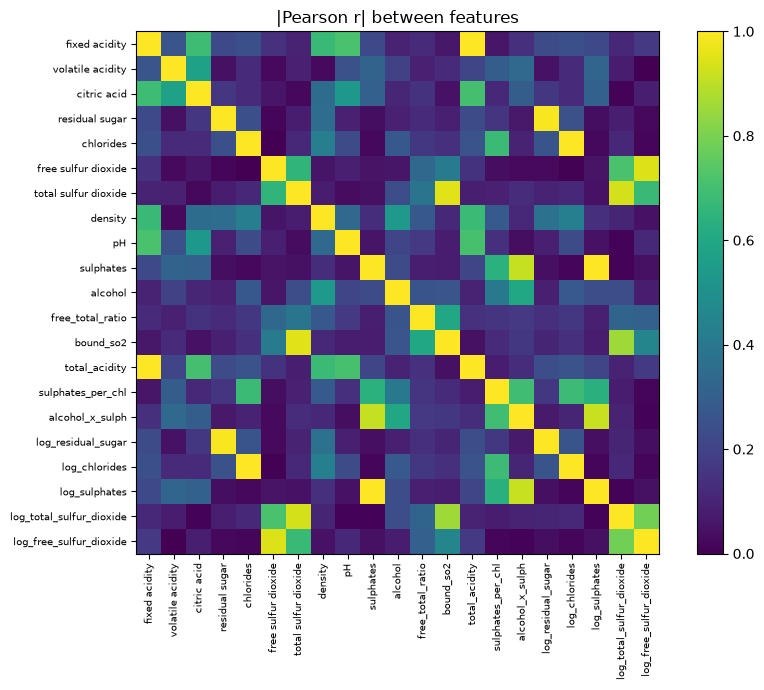

In [12]:
cm = Xf.corr().abs()
pairs = [(a, b, cm.loc[a, b]) for i, a in enumerate(cm.columns) for b in cm.columns[i+1:] if cm.loc[a, b] >= 0.7]
print("Pairs with |r| >= 0.70:")
for a, b, val in sorted(pairs, key=lambda t: -t[2]): print(f" {a:26s} {b:26s} {val:.3f}")
    
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(cm.values, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(len(cm))); ax.set_xticklabels(cm.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(cm))); ax.set_yticklabels(cm.columns, fontsize=7)
plt.colorbar(im); ax.set_title("|Pearson r| between features"); plt.tight_layout(); plt.show()

In [ ]:
**Check.** Most high-correlation pairs are features I created: each `log_*` is 0.94–1.00 correlated with its raw column and added nothing in Step 4.
Decisions:

- Drop all five `log_*` columns (duplicate the raw columns).
- Drop `total_acidity` (r = 0.996 with `fixed acidity`) and `bound_so2` (r = 0.956 with `total sulfur dioxide`).
- Drop `alcohol_x_sulph` (r = 0.91 with `sulphates`; its signal comes from `alcohol` and `sulphates`, which are kept, and tree models can find the
interaction themselves).
- Drop `pH` and `residual sugar` (irrelevant per 5b).
That leaves 11 candidates; check them with VIF.

In [ ]:
5d. Variance inflation factor (VIF)

In [13]:
def vif_table(cols): 
    X_ = fe[cols] 
    return pd.Series({c: 1/(1 - LinearRegression().fit(X_.drop(columns=c), X_[c]).score(X_.drop(columns=c), X_[c])) for c in cols}
                    ).sort_values(ascending=False)

cand11 = ["fixed acidity","volatile acidity","citric acid","chlorides","free sulfur dioxide","total sulfur dioxide", 
          "density","sulphates","alcohol","free_total_ratio","sulphates_per_chl"]
print("VIF, 11 candidates (>5 concerning, >10 severe):"); print(vif_table(cand11).round(2).to_string())

VIF, 11 candidates (>5 concerning, >10 severe):
sulphates_per_chl       9.78
total sulfur dioxide    7.08
free sulfur dioxide     6.70
chlorides               5.48
sulphates               5.47
free_total_ratio        4.68
density                 3.98
fixed acidity           3.69
citric acid             3.11
alcohol                 2.07
volatile acidity        1.82


In [ ]:
**Check.** Pairwise correlations are fine, but VIF flags `sulphates_per_chl` (9.8, built from two features already kept) and the sulfur-dioxide group
(4.7–7.1). Drop both ratio features and re-check.

In [14]:
FEATURES = ["fixed acidity","volatile acidity","citric acid","chlorides","free sulfur dioxide", 
            "total sulfur dioxide","density","sulphates","alcohol"]
print("VIF, final 9 features:"); print(vif_table(FEATURES).round(2).to_string())
print("\nFinal feature count:", len(FEATURES), "| max VIF:", round(vif_table(FEATURES).max(), 2))
data = fe[FEATURES + ["good", "quality"]]

VIF, final 9 features:
density                 3.74
fixed acidity           3.67
citric acid             3.10
total sulfur dioxide    2.09
alcohol                 2.06
free sulfur dioxide     1.90
volatile acidity        1.82
sulphates               1.28
chlorides               1.26

Final feature count: 9 | max VIF: 3.74


In [ ]:
**Check.** 9 features, max VIF 3.74 — multicollinearity resolved. **None of the engineered features survived selection**; once collinearity is
accounted for they were redundant with the raw columns. That is a legitimate result, and better than keeping features that add only noise.

In [ ]:
Step 6 — Split, scaling, dummy variables

- **Split:** 80/20 `train_test_split`, **stratified** on the target so both sets keep the ~13.4% positive rate.
- **Scaling:** **standardization** for Logistic Regression, SVM and KNN (scale-sensitive; density ≈ 1 vs total SO₂ ≈ 40). Tree ensembles don't need
it. The scaler is fit on training data only.
- **Dummy variables:** none needed — every feature is numeric.

In [15]:
X = data[FEATURES]; y = data.good; q = data.quality
Xtr, Xte, ytr, yte, qtr, qte = train_test_split(X, y, q, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", Xtr.shape, "| positives:", ytr.sum(), f"({ytr.mean():.1%})")
print("Test: ", Xte.shape, "| positives:", yte.sum(), f"({yte.mean():.1%})")
print("Majority-class baseline accuracy on test:", round(1 - yte.mean(), 3))

Z = StandardScaler().fit(Xtr).transform(Xtr)
print("\nScaled train: max |mean| =", abs(Z.mean(0)).max().round(6), "| std =", np.unique(Z.std(0).round(2)))

Train: (976, 9) | positives: 130 (13.3%)
Test:  (244, 9) | positives: 33 (13.5%)
Majority-class baseline accuracy on test: 0.865

Scaled train: max |mean| = 0.0 | std = [1.]


In [ ]:
**Check.** The stratified split holds (train 13.3%, test 13.5% positive) and scaling is verified (mean 0, std 1). The majority-class baseline is
**86.5% accuracy** — this is the number any model must be judged against.

In [ ]:
Step 7 — Balancing and model comparison

**Validation:** 5-fold stratified cross-validation on the training set for all comparisons; the test set is kept for the final check. With only 130
positives in training, CV gives a more stable comparison than one split.
    
**Metrics:** accuracy is misleading here, so I report precision, recall, F1, ROC-AUC and PR-AUC.

In [ ]:
7a. Does the data need balancing? (SMOTE is applied inside each CV fold, never on validation folds)

In [16]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
scoring = ("accuracy", "precision", "recall", "f1", "roc_auc", "average_precision")
cfg = { 
 "LogReg  none": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), 
 "LogReg  weights": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")), 
 "LogReg  SMOTE": make_pipeline(StandardScaler(), SMOTE(random_state=SEED), LogisticRegression(max_iter=1000)), 
 "RF      none": RandomForestClassifier(300, min_samples_leaf=2, random_state=SEED), 
 "RF      weights": RandomForestClassifier(300, min_samples_leaf=2, class_weight="balanced_subsample", random_state=SEED), 
 "RF      SMOTE": make_pipeline(SMOTE(random_state=SEED), RandomForestClassifier(300, min_samples_leaf=2, random_state=SEED)),
}
print(f"{'config':16s} {'acc':>6s} {'prec':>6s} {'recall':>7s} {'F1':>6s} {'ROC-AUC':>8s} {'PR-AUC':>7s}")
for n, m in cfg.items(): 
    s = cross_validate(m, Xtr, ytr, cv=cv, scoring=scoring) 
    print(f"{n:16s} " + " ".join(f"{s['test_'+k].mean():6.3f}" for k in scoring))

config              acc   prec  recall     F1  ROC-AUC  PR-AUC
LogReg  none      0.882  0.593  0.338  0.430  0.885  0.543
LogReg  weights   0.793  0.381  0.831  0.520  0.884  0.549
LogReg  SMOTE     0.801  0.393  0.831  0.530  0.883  0.552
RF      none      0.892  0.688  0.346  0.457  0.868  0.596
RF      weights   0.881  0.580  0.408  0.475  0.867  0.590
RF      SMOTE     0.841  0.437  0.608  0.507  0.869  0.552


In [ ]:
**Check.** Balancing does **not** improve how well the model *ranks* wines (ROC-AUC and PR-AUC are unchanged). It moves the decision threshold along
the precision/recall tradeoff: for Logistic Regression, recall rises from 0.34 to 0.83, precision falls from 0.59 to 0.38, accuracy falls from 0.88 to
0.79, and F1 improves from 0.43 to 0.52. Without balancing the model misses two of every three good wines. `class_weight` and SMOTE perform about the
same, so the simpler `class_weight` is used.
    
**Yes, balance the data** if the goal is to catch good wines.

In [ ]:
7b. Which algorithm?

In [17]:
models = { 
 "Baseline (majority)": DummyClassifier(), 
 "LogReg (weighted)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")), 
 "SVM RBF (weighted)": make_pipeline(StandardScaler(), SVC(class_weight="balanced", probability=True, random_state=SEED)), 
 "KNN (k=15, scaled)": make_pipeline(StandardScaler(), KNeighborsClassifier(15)), 
 "RandomForest (wtd)": RandomForestClassifier(300, min_samples_leaf=2, class_weight="balanced_subsample", random_state=SEED), 
 "GradBoost":          GradientBoostingClassifier(n_estimators=150, max_depth=3, learning_rate=0.05, random_state=SEED),
}
print(f"{'model':20s} {'acc':>6s} {'prec':>6s} {'recall':>7s} {'F1':>6s} {'ROC-AUC':>8s} {'PR-AUC':>7s}")
for n, m in models.items(): 
    s = cross_validate(m, Xtr, ytr, cv=cv, scoring=scoring) 
    print(f"{n:20s} " + " ".join(f"{np.nan_to_num(s['test_'+k].mean()):6.3f}" for k in scoring))

model                   acc   prec  recall     F1  ROC-AUC  PR-AUC
Baseline (majority)   0.867  0.000  0.000  0.000  0.500  0.133
LogReg (weighted)     0.793  0.381  0.831  0.520  0.884  0.549
SVM RBF (weighted)    0.796  0.376  0.777  0.505  0.863  0.552
KNN (k=15, scaled)    0.880  0.595  0.331  0.420  0.844  0.478
RandomForest (wtd)    0.881  0.580  0.408  0.475  0.867  0.590
GradBoost             0.891  0.647  0.400  0.492  0.869  0.581


In [ ]:
**Check.** Weighted Logistic Regression has the best ROC-AUC (0.884), recall (0.83) and F1 (0.52). Random Forest has the best PR-AUC (0.59); Gradient
Boosting the best precision and accuracy, but both catch only ~40% of good wines. Differences between the real models are small relative to fold
noise, so I choose on **simplicity and interpretability: weighted Logistic Regression**.

In [ ]:
Step 8 — Final evaluation on the held-out test set

The decision threshold is tuned on **out-of-fold training predictions** so the test set stays untouched for that choice.

In [18]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
oof = cross_val_predict(lr, Xtr, ytr, cv=cv, method="predict_proba")[:, 1]
ts = np.arange(.2, .95, .01); f = [f1_score(ytr, oof >= t) for t in ts]; tbest = ts[int(np.argmax(f))]
print(f"Best CV threshold for F1: {tbest:.2f} (F1={max(f):.3f}) vs default 0.50 (F1={f1_score(ytr, oof >= .5):.3f})")

lr.fit(Xtr, ytr); p = lr.predict_proba(Xte)[:, 1]
rf = RandomForestClassifier(300, min_samples_leaf=2, class_weight="balanced_subsample", random_state=SEED).fit(Xtr, ytr)
prf = rf.predict_proba(Xte)[:, 1]

def rep(name, pr, t): 
    yh = (pr >= t).astype(int); tn, fp, fn, tp = confusion_matrix(yte, yh).ravel() 
    print(f"{name:34s} acc={accuracy_score(yte, yh):.3f} prec={precision_score(yte, yh):.3f} " 
          f"rec={recall_score(yte, yh):.3f} F1={f1_score(yte, yh):.3f} | TP={tp} FN={fn} FP={fp} TN={tn}")

print(f"\nTEST SET (n={len(yte)}, {yte.sum()} good wines)")
print(f"ROC-AUC LR={roc_auc_score(yte, p):.3f} RF={roc_auc_score(yte, prf):.3f} | " 
      f"PR-AUC LR={average_precision_score(yte, p):.3f} RF={average_precision_score(yte, prf):.3f}\n")
rep("LogReg weighted @0.50", p, .5)
rep(f"LogReg weighted @{tbest:.2f} (tuned)", p, tbest)
rep("RandomForest weighted @0.50", prf, .5)

Best CV threshold for F1: 0.66 (F1=0.566) vs default 0.50 (F1=0.517)

TEST SET (n=244, 33 good wines)
ROC-AUC LR=0.866 RF=0.872 | PR-AUC LR=0.481 RF=0.619

LogReg weighted @0.50              acc=0.783 prec=0.372 rec=0.879 F1=0.523 | TP=29 FN=4 FP=49 TN=162
LogReg weighted @0.66 (tuned)      acc=0.811 prec=0.390 rec=0.697 F1=0.500 | TP=23 FN=10 FP=36 TN=175
RandomForest weighted @0.50        acc=0.898 prec=0.654 rec=0.515 F1=0.576 | TP=17 FN=16 FP=9 TN=202


Logistic Regression standardized coefficients:
total sulfur dioxide   -0.605
volatile acidity       -0.511
density                -0.451
citric acid            -0.231
chlorides              -0.036
free sulfur dioxide     0.187
fixed acidity           0.631
sulphates               0.697
alcohol                 1.086


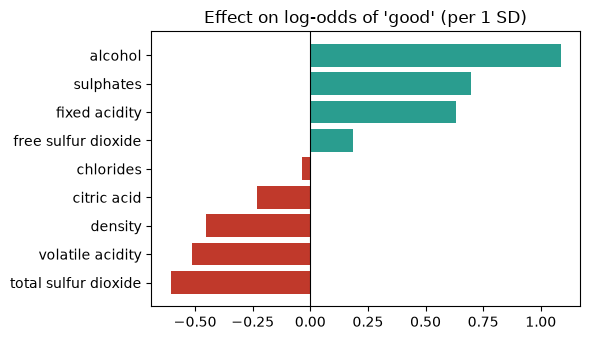

In [19]:
coef = pd.Series(lr[-1].coef_[0], index=FEATURES).sort_values()
print("Logistic Regression standardized coefficients:"); print(coef.round(3).to_string())
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(coef.index, coef.values, color=["#c0392b" if v < 0 else "#2a9d8f" for v in coef.values])
ax.axvline(0, color="k", lw=.8); ax.set_title("Effect on log-odds of 'good' (per 1 SD)")
plt.tight_layout(); plt.show()

In [ ]:
**Check.**

- **Logistic Regression** @0.50 catches 29 of 33 good wines (recall 0.88) but raises 49 false alarms (precision 0.37). The CV-tuned threshold (0.66)
did *not* help on test (F1 0.50 vs 0.52) — the difference is within noise.
- **Random Forest** scores better on test (F1 0.56, PR-AUC 0.62, precision 0.67) but misses half the good wines. It ranked behind Logistic Regression
in CV; with only 33 positives, switching models because it looks better on the test set would be overfitting to the test set, so the two are treated
as comparable.
- The coefficients are chemically sensible: **alcohol**, **sulphates** and fixed acidity raise the odds of a good wine; **volatile acidity** (vinegar
taint), **total SO₂** and density lower them.

In [ ]:
Step 9 — Why is the model only mediocre?

Test precision is low (many false alarms). Hypothesis: the false positives are mostly quality-6 wines, one point below the cutoff, where taster
judgment decides. Also quantify how uncertain the test metrics are.

In [20]:
yh = (p >= .5).astype(int); fp = (yh == 1) & (yte == 0)
print("False positives by true quality:", qte[fp].value_counts().sort_index().to_dict())
print(f"Share of false positives that are quality 6: {(qte[fp] == 6).mean():.0%}")
print("\nMean predicted P(good) by true quality (test set):")
print(pd.Series(p, index=qte.index).groupby(qte).mean().round(3).to_string())

rng = np.random.default_rng(0); f1s, aucs = [], []; yt = yte.to_numpy()
for _ in range(2000): 
    i = rng.integers(0, len(yt), len(yt)) 
    if yt[i].sum() == 0: continue 
    f1s.append(f1_score(yt[i], yh[i])); aucs.append(roc_auc_score(yt[i], p[i]))
print(f"\nBootstrap 95% CI on test: F1 {np.percentile(f1s, 2.5):.2f}-{np.percentile(f1s, 97.5):.2f}"
      f" | ROC-AUC {np.percentile(aucs, 2.5):.2f}-{np.percentile(aucs, 97.5):.2f}")

False positives by true quality: {5: 7, 6: 42}
Share of false positives that are quality 6: 86%

Mean predicted P(good) by true quality (test set):
quality
3    0.020
4    0.090
5    0.146
6    0.427
7    0.702
8    0.803

Bootstrap 95% CI on test: F1 0.40-0.63 | ROC-AUC 0.80-0.92


In [ ]:
**Check — hypothesis confirmed.** 86% of false positives are quality-6 wines. Predicted probability rises smoothly with true quality (0.02 → 0.09 →
0.15 → 0.43 → 0.70 → 0.80 for scores 3–8), so the model has learned the real quality gradient; most of its "errors" are borderline wines. Test
uncertainty is large: F1 95% CI 0.40–0.63.
    
**Why not better:**
1. **Noisy, boundary-based label.** Quality is the median of a few human tasters; "good" is a cutoff through a continuous judgment.
2. **Missing information.** Lab chemistry doesn't capture aroma compounds, grape variety, vintage or terroir.
3. **Very few positives.** 163 good wines total, 33 in the test set, so every metric is noisy and small model differences shouldn't be over-trusted.
4. **Precision/recall tradeoff.** The right operating point depends on use: a screening tool should favor recall; selecting wines to market as premium
should favor precision.

In [ ]:
Step 10 — Summary: answers to the assignment questions

| Question | Answer |
|---|---|
| Dataset / target / goal | Red wine, 1,599 samples, 11 chemical features. Predict **good wine (quality ≥ 7)**, 13.6% positive. |
| Unwanted features, missing values, duplicates | No ID columns, no missing values. **240 duplicates (15%) removed.** |
| Inconsistent categories / encoding | No categorical columns, so nothing to encode. |
| Outliers | 1.5×IQR would remove 25% of rows and 31.5% of good wines; used **3×IQR** (139 rows removed). |
| Feature engineering | Log transforms, ratios, interactions created; none survived collinearity checks. |
| Zero / low variance | None. |
| Irrelevant features | `pH`, `residual sugar` (ANOVA p > 0.05). |
| Highly correlated features | log versions, `total_acidity`, `bound_so2`, `alcohol_x_sulph`, ratio features — removed. Final VIF ≤ 3.74 with 9
features. |
| Normalize or standardize? | **Standardize** for Logistic Regression / SVM / KNN; trees need no scaling. |
| Dummy variables? | None needed (all numeric). |
| Balance the data? | **Yes** — `class_weight='balanced'` (SMOTE performed about the same). |
| train_test_split or CV? | **Both:** stratified 80/20 split for the final test, 5-fold stratified CV for model comparison. |
| Algorithm | Weighted **Logistic Regression** (interpretable; statistically comparable to Random Forest). |
| Metrics | ROC-AUC, PR-AUC, precision, recall, F1 (accuracy is misleading at 86.5% baseline). |
| Quality of the model | ROC-AUC ≈ 0.87 (good ranking); F1 ≈ 0.5 (moderate). Weakness is precision: false positives are mostly borderline quality-6
wines. |